# 03 — Pipeline đầu vào và phương pháp đánh giá

Notebook kiểm tra Dataset, phép biến đổi ảnh–mask, DataLoader và metric trước khi huấn luyện. Logic được triển khai trong các module Python dùng chung; các ô dưới minh họa đầu vào và kiểm tra những trường hợp có kết quả xác định trước.

Đầu vào gồm dữ liệu và split cố định từ bước 2. Notebook chỉ đọc train/validation, không tải dữ liệu, phân chia lại tập hoặc huấn luyện mô hình. Test và CVC-ClinicDB được giữ cho đánh giá cuối.

## 3.1 — Môi trường và cấu hình

Sử dụng môi trường đã cài `requirements-training.txt`; không bắt buộc GPU cho các kiểm tra này. `configs/unet.yaml` quy định preprocessing, DataLoader và cấu hình M1 được sử dụng ở notebook 04. Đường dẫn được xác định theo gốc repository, không phụ thuộc cấu trúc thư mục của một máy cụ thể.

In [1]:
import sys
from pathlib import Path

start = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (start, *start.parents)
                     if (p / "src/datasets").is_dir() and (p / "README.md").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Mở notebook trong cây thư mục repo.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import torch
from PIL import Image
from IPython.display import display
from src.utils import load_config, seed_everything
from src.datasets.dataset import create_dataloaders
from src.datasets.preview import save_transform_preview
from src.metrics import binary_metrics, metrics_at_original_size

config = load_config(PROJECT_ROOT / "configs/unet.yaml")
print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Cấu hình input:", config["data"]["image_size"])


Python: d:\anaconda\envs\data_processing\python.exe
PyTorch: 2.9.1+cu126
Cấu hình input: [256, 256]


## 3.2 — Đọc batch và chuẩn hóa đầu vào

Dataset đọc ảnh theo ID trong split cố định, chuyển ảnh sang RGB và mask sang grayscale. Nhãn polyp được xác định bởi pixel >127, cho target nhị phân 0/1.

Ảnh được resize bằng bilinear, mask bằng nearest-neighbor, cùng giữ tỷ lệ để vừa khung 256×256. Padding đặt nội dung ở giữa; chênh lệch hai phía tối đa một pixel, phần dư nằm bên phải hoặc phía dưới. Ví dụ, ảnh 800×400 pixel được resize thành 256×128 rồi bổ sung 64 pixel trên và dưới.

Padding RGB bằng 0 trước chuẩn hóa ImageNet, padding mask bằng 0. `valid_mask` có kiểu bool và shape `[B,1,H,W]`, phân biệt vùng nội dung với nền nhân tạo. Loss BCE+Dice của M1 sử dụng mask này để loại padding khỏi phép tính.

Mỗi mẫu trả metadata `geometry`, gồm kích thước gốc, kích thước sau augmentation, kích thước nội dung sau resize, kích thước khung và padding `(left, top, right, bottom)`. Các kích thước hình học dùng thứ tự `(height, width)`.

Train được shuffle; validation không shuffle hoặc augmentation ngẫu nhiên. Mask validation được giữ thêm ở độ phân giải gốc dưới dạng danh sách để hỗ trợ ảnh có kích thước khác nhau. Seed chia dữ liệu được giữ cố định khi thay đổi seed huấn luyện.

In [2]:
loaders = create_dataloaders(PROJECT_ROOT, config)
train_batch = next(iter(loaders["train"]))
val_batch = next(iter(loaders["val"]))
print("Số mẫu:", {name: len(loader.dataset) for name, loader in loaders.items()})
print("Ảnh train:", tuple(train_batch["image"].shape), train_batch["image"].dtype)
print("Mask train:", tuple(train_batch["mask"].shape), train_batch["mask"].unique().tolist())
print("ID đầu:", train_batch["image_id"][0])
print("Kích thước mask gốc validation:", [tuple(m.shape) for m in val_batch["original_mask"]])
assert torch.isfinite(train_batch["image"]).all()
assert set(train_batch["mask"].unique().tolist()) <= {0, 1}

print("Geometry validation đầu tiên:", val_batch["geometry"][0])
print("Shape valid_mask:", tuple(train_batch["valid_mask"].shape))
print("Pixel ảnh thật mỗi mẫu:", train_batch["valid_mask"].flatten(1).sum(1).tolist())
assert not train_batch["mask"][~train_batch["valid_mask"]].any()
for geometry in val_batch["geometry"]:
    left, top, right, bottom = geometry["padding"]
    assert abs(left - right) <= 1 and abs(top - bottom) <= 1


Số mẫu: {'train': 700, 'val': 150}
Ảnh train: (8, 3, 256, 256) torch.float32
Mask train: (8, 1, 256, 256) [0.0, 1.0]
ID đầu: Kvasir-SEG/cju8clorgsuwn08714toqb7v6.jpg
Kích thước mask gốc validation: [(1, 528, 622), (1, 1019, 1214), (1, 530, 611), (1, 546, 609), (1, 547, 620), (1, 531, 622), (1, 531, 480), (1, 529, 622)]
Geometry validation đầu tiên: {'source_size': (528, 622), 'input_size': (256, 256), 'resized_size': (217, 256), 'padding': (0, 19, 0, 20), 'original_size': (528, 622), 'augmented': False}
Shape valid_mask: (8, 1, 256, 256)
Pixel ảnh thật mỗi mẫu: [60928, 57088, 55552, 55808, 61696, 57088, 57088, 62208]


## 3.3 — Kiểm tra trực quan preprocessing và augmentation

Hình minh họa gồm bốn cột: ảnh gốc, overlay ground truth, letterbox cố định và augmentation kết hợp letterbox. Khung xanh đánh dấu vùng nội dung; phần bên ngoài là padding. Cột xử lý cố định sử dụng cùng ảnh train để đối chiếu, không đại diện cho một mẫu validation riêng biệt.

Augmentation gồm lật ngang và lật dọc với xác suất 0.5 cho mỗi phép, cùng xoay ngẫu nhiên một trong bốn góc 0°, 90°, 180°, 270°. Các biến đổi hình học được áp dụng đồng bộ cho ảnh và mask trước resize/padding, chỉ khi đọc mẫu train.

Ảnh hiển thị được đảo chuẩn hóa về RGB. Các overlay sử dụng nhãn thật. Tensor sau xử lý được tạo trong bộ nhớ; việc hiển thị không ghi đè dữ liệu nguồn.

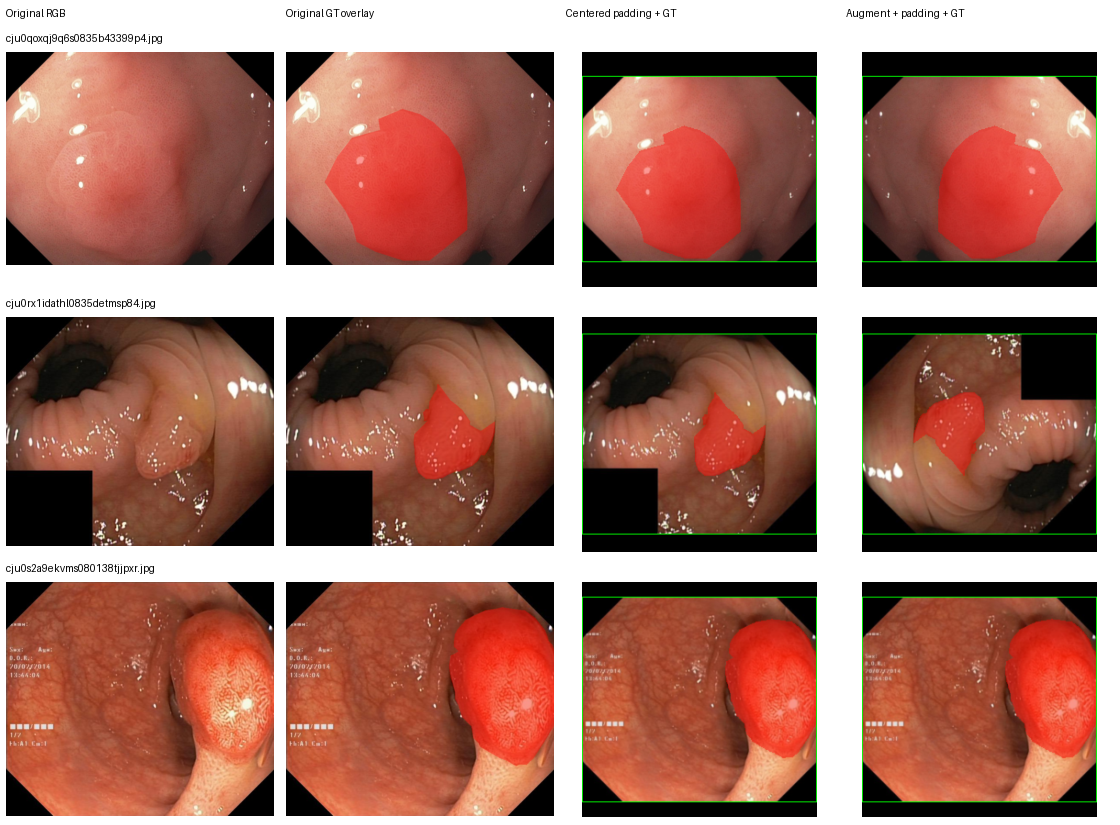

Hình: results\figures\step3_transforms.png


In [3]:
seed_everything(config["seed"])
figure_path = save_transform_preview(
    loaders["train"].dataset, PROJECT_ROOT / "results/figures/step3_transforms.png")
with Image.open(figure_path) as image:
    display(image.copy())
print("Hình:", figure_path.relative_to(PROJECT_ROOT))


## 3.4 — Kiểm tra công thức metric

Dice, IoU, Precision và Recall được tính riêng cho từng ảnh. Điểm của tập dữ liệu là trung bình theo số ảnh, không phải phép tính trên toàn bộ pixel gộp chung.

Nếu dự đoán và nhãn đều rỗng, Dice/IoU bằng 1; nếu chỉ một bên rỗng, điểm bằng 0. Precision/Recall được quy ước bằng 0 khi mẫu số bằng 0. Metric nhị phân được phân biệt với soft Dice dùng trong loss huấn luyện.

Ví dụ kiểm tra bên dưới có TP=1, hai pixel dương dự đoán và hai pixel dương ground truth, tương ứng Dice=0.5 và IoU=1/3. Mẫu thứ hai có hai mask rỗng nên Dice/IoU bằng 1. Các giá trị này kiểm chứng công thức, không phải kết quả thực nghiệm của mô hình.

In [4]:
truth = torch.tensor([[[1., 1., 0.]], [[0., 0., 0.]]])
prediction = torch.tensor([[[1., 0., 1.]], [[0., 0., 0.]]])
scores = binary_metrics(prediction, truth, from_logits=False)
print({name: value.tolist() for name, value in scores.items()})
print("Dice trung bình hai ảnh:", scores["dice"].mean().item())
assert torch.allclose(scores["dice"], torch.tensor([0.5, 1.]))


{'dice': [0.5, 1.0], 'iou': [0.3333333432674408, 1.0], 'precision': [0.5, 0.0], 'recall': [0.5, 0.0]}
Dice trung bình hai ảnh: 0.75


## 3.5 — Khôi phục dự đoán về độ phân giải gốc

`metrics_at_original_size` sử dụng metadata hình học để đánh giá theo thứ tự:

1. Đưa logits decoder về khung đầu vào nếu decoder có độ phân giải thấp hơn.
2. Loại bỏ padding theo tọa độ đã lưu.
3. Resize logits của vùng nội dung về kích thước ảnh gốc.
4. Áp dụng sigmoid, nhị phân hóa tại xác suất ≥0.5 và so sánh với mask gốc.

Mask ground truth gốc được giữ nguyên để tính điểm chính. Khi tính metric tại độ phân giải đầu vào, `binary_metrics` nhận thêm `valid_mask` để loại vùng padding.

Ví dụ bên dưới sử dụng logits nền giả lập nhằm kiểm tra luồng khôi phục, không đánh giá một model đã huấn luyện. Khi tổng hợp nhiều batch, cần cộng điểm từng ảnh rồi chia tổng số ảnh để tránh sai lệch do batch cuối nhỏ hơn.

In [5]:
dummy_logits = torch.full_like(val_batch["mask"], -20)
original_scores = metrics_at_original_size(
    dummy_logits, val_batch["original_mask"], val_batch["geometry"], threshold=config["evaluation"]["threshold"])
print("Số điểm metric từng ảnh:", {name: value.numel() for name, value in original_scores.items()})
assert original_scores["dice"].numel() == len(val_batch["image_id"])


Số điểm metric từng ảnh: {'dice': 8, 'iou': 8, 'precision': 8, 'recall': 8}
